Normalization functions imported successfully.

Processing: P2658
Selected slice: 92
Mask pixels: 32555


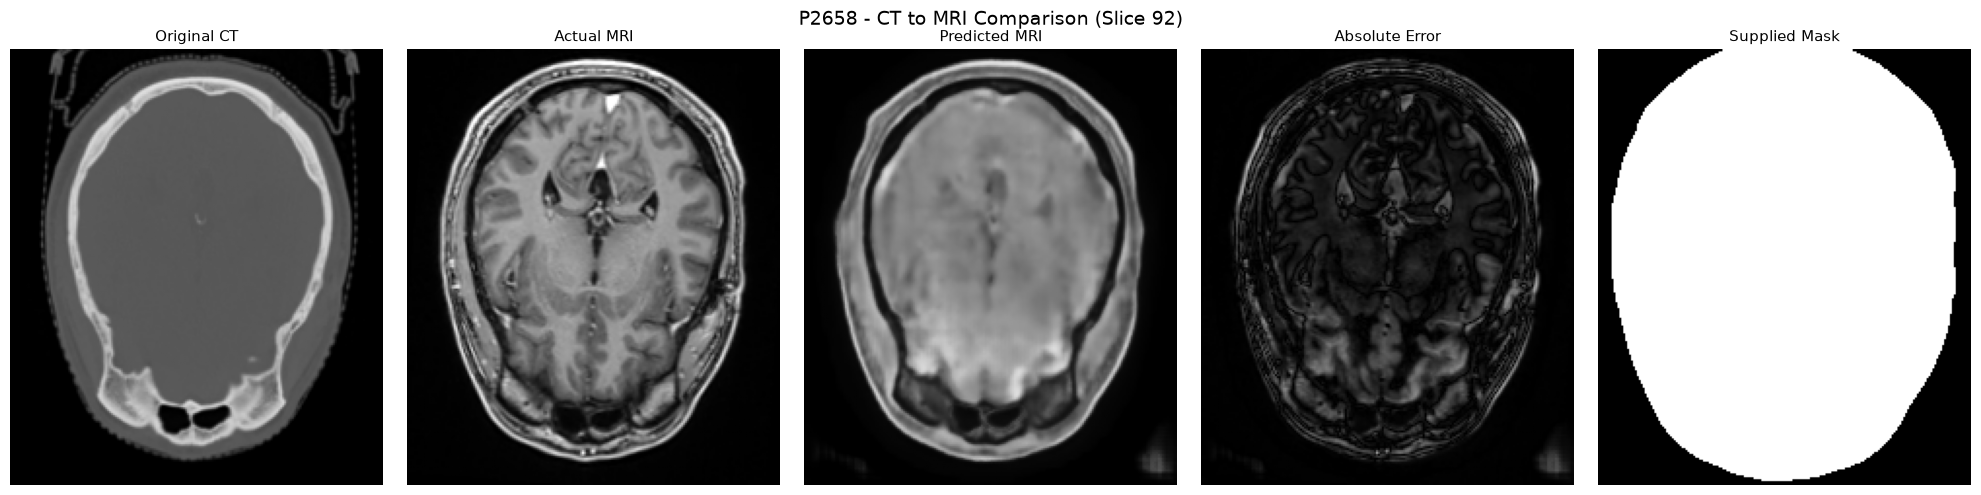

Saved: D:\PS07_CT2MRI\outputs\visualizations\P2658_comparison.png

Processing: P6123
Selected slice: 81
Mask pixels: 35344


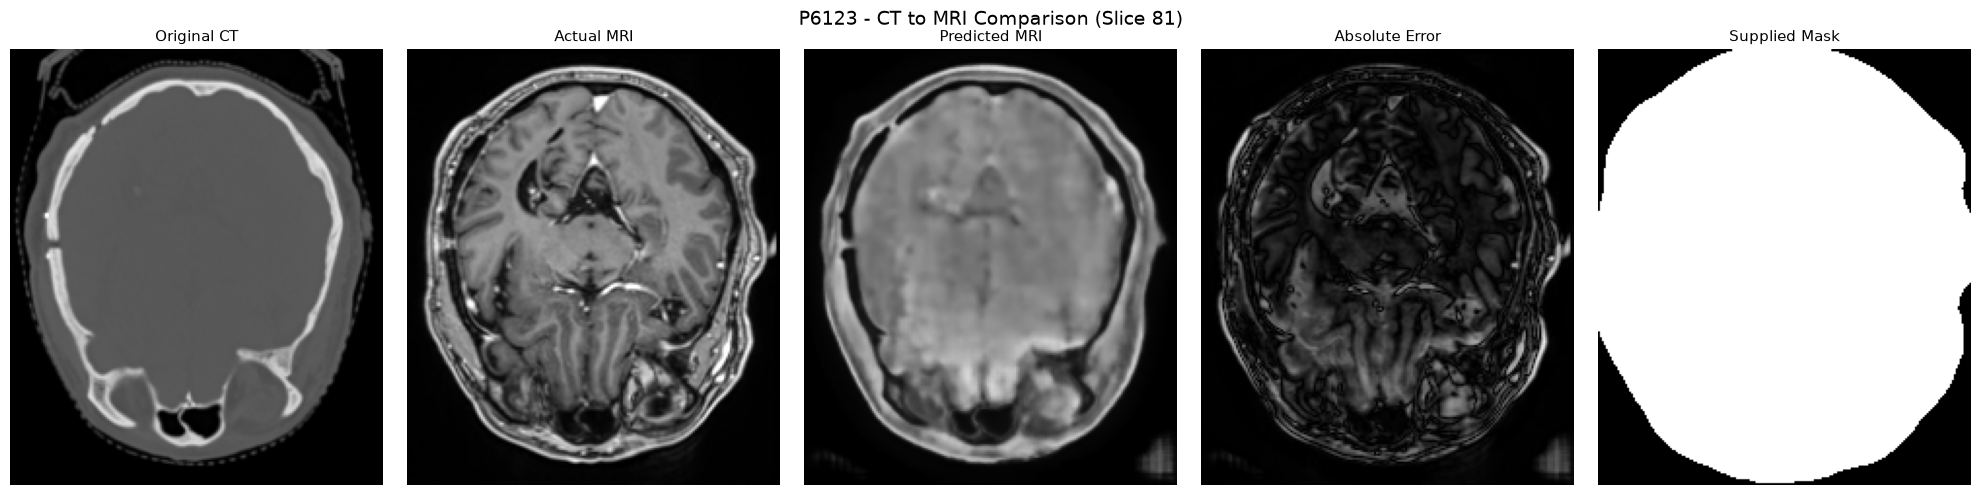

Saved: D:\PS07_CT2MRI\outputs\visualizations\P6123_comparison.png

Processing: P7363
Selected slice: 80
Mask pixels: 29349


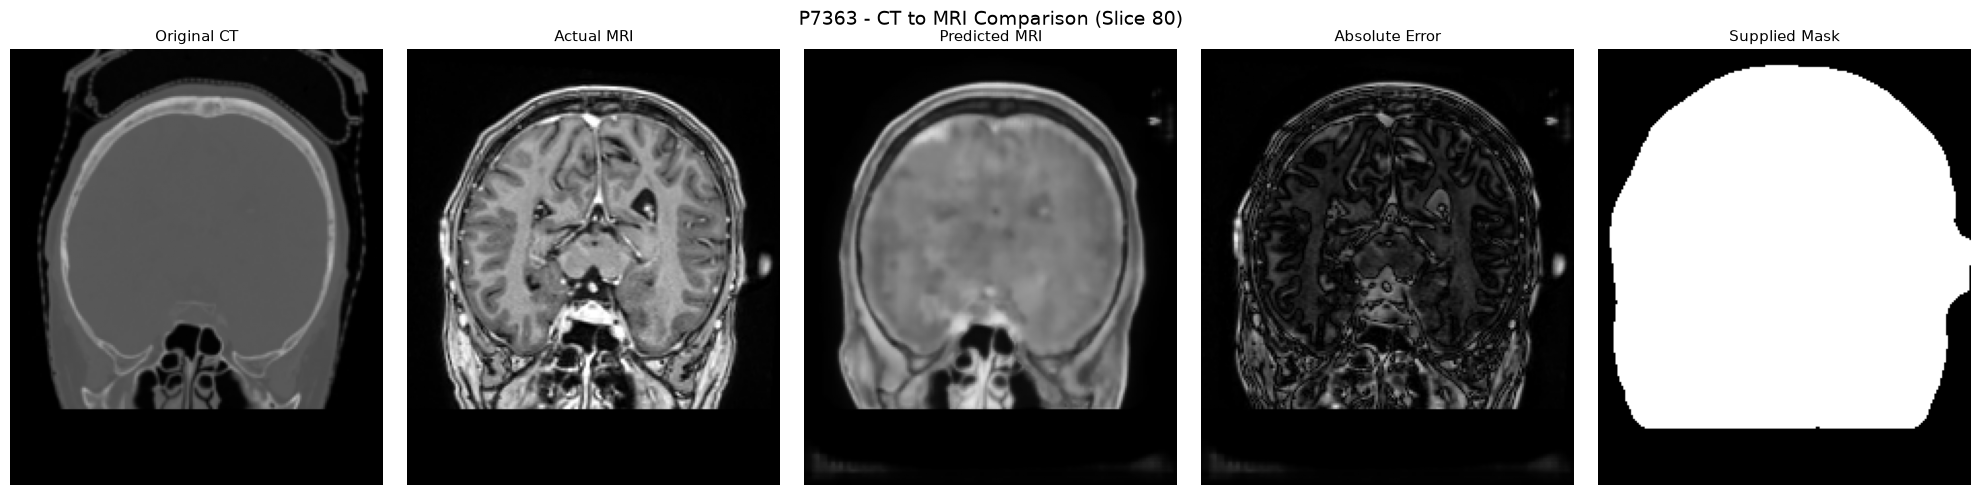

Saved: D:\PS07_CT2MRI\outputs\visualizations\P7363_comparison.png

Processing: P7480
Selected slice: 102
Mask pixels: 29078


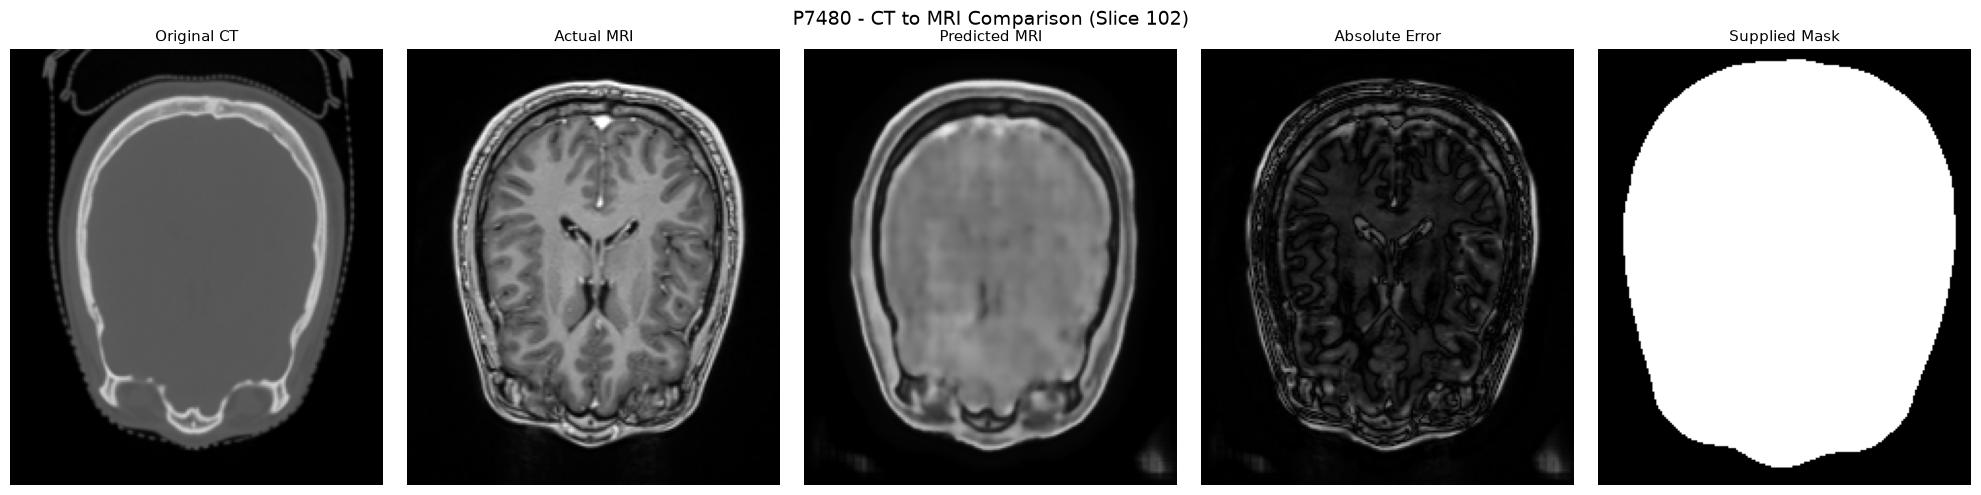

Saved: D:\PS07_CT2MRI\outputs\visualizations\P7480_comparison.png

Processing: P8947
Selected slice: 105
Mask pixels: 30232


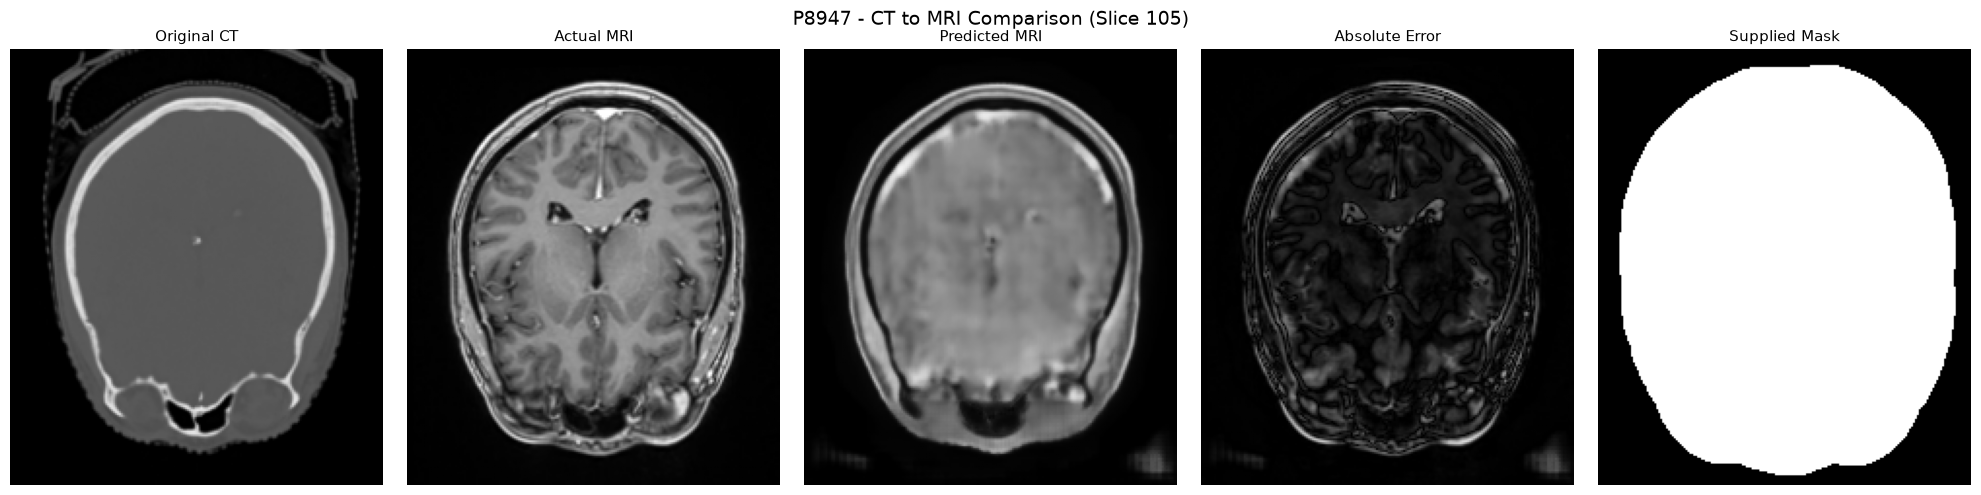

Saved: D:\PS07_CT2MRI\outputs\visualizations\P8947_comparison.png

ALL VISUALIZATIONS COMPLETED
Output folder: D:\PS07_CT2MRI\outputs\visualizations


In [2]:

import sys
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

ROOT = Path(r"D:\PS07_CT2MRI")

VOLUME_DIR = ROOT / "dataset" / "volumes"
PRED_DIR = ROOT / "outputs" / "validation"
FIG_DIR = ROOT / "outputs" / "visualizations"

FIG_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. FIX PYTHON IMPORT PATH
# --------------------------------------------------

sys.path.insert(0, str(ROOT / "dataset"))

from normalise import normalise_ct, normalise_mri

print("Normalization functions imported successfully.")

# --------------------------------------------------
# 3. VALIDATION PATIENTS
# --------------------------------------------------

patient_ids = [
    "P2658",
    "P6123",
    "P7363",
    "P7480",
    "P8947"
]

# --------------------------------------------------
# 4. VISUALIZE EACH PATIENT
# --------------------------------------------------

for patient_id in patient_ids:

    print("\nProcessing:", patient_id)

    patient_dir = VOLUME_DIR / patient_id

    # Load original images
    ct_img = nib.load(str(patient_dir / "ct.nii.gz"))
    mr_img = nib.load(str(patient_dir / "mr.nii.gz"))
    mask_img = nib.load(str(patient_dir / "mask.nii.gz"))

    # Load predicted MRI
    pred_path = PRED_DIR / f"{patient_id}_predicted_mri.nii.gz"

    if not pred_path.exists():
        print("Prediction not found:", pred_path)
        continue

    pred_img = nib.load(str(pred_path))

    # Convert to NumPy arrays
    ct = ct_img.get_fdata().astype(np.float32)
    mr = mr_img.get_fdata().astype(np.float32)
    mask = mask_img.get_fdata().astype(np.uint8)
    pred = pred_img.get_fdata().astype(np.float32)

    # Verify dimensions
    assert ct.shape == mr.shape == mask.shape == pred.shape, (
        f"Shape mismatch for {patient_id}"
    )

    # --------------------------------------------------
    # 5. APPLY OFFICIAL NORMALIZATION
    # --------------------------------------------------

    ct_norm = normalise_ct(ct)
    mr_norm = normalise_mri(mr, mask)

    # --------------------------------------------------
    # 6. SELECT SLICE WITH LARGEST MASK AREA
    # --------------------------------------------------

    mask_counts = np.sum(mask > 0, axis=(0, 1))

    z = int(np.argmax(mask_counts))

    print("Selected slice:", z)
    print("Mask pixels:", int(mask_counts[z]))

    # --------------------------------------------------
    # 7. CALCULATE ABSOLUTE ERROR
    # --------------------------------------------------

    actual_slice = mr_norm[:, :, z]
    predicted_slice = np.clip(pred[:, :, z], 0, 1)

    error = np.abs(actual_slice - predicted_slice)

    # --------------------------------------------------
    # 8. CREATE COMPARISON FIGURE
    # --------------------------------------------------

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    images = [
        (ct_norm[:, :, z], "Original CT"),
        (actual_slice, "Actual MRI"),
        (predicted_slice, "Predicted MRI"),
        (error, "Absolute Error"),
        (mask[:, :, z], "Supplied Mask")
    ]

    for ax, (image, title) in zip(axes, images):

        ax.imshow(
            image.T,
            cmap="gray",
            origin="lower",
            vmin=0,
            vmax=1
        )

        ax.set_title(title, fontsize=11)
        ax.axis("off")

    fig.suptitle(
        f"{patient_id} - CT to MRI Comparison (Slice {z})",
        fontsize=14
    )

    plt.tight_layout()

    # --------------------------------------------------
    # 9. SAVE FIGURE
    # --------------------------------------------------

    save_path = FIG_DIR / f"{patient_id}_comparison.png"

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

# --------------------------------------------------
# 10. COMPLETION
# --------------------------------------------------

print("\n================================")
print("ALL VISUALIZATIONS COMPLETED")
print("================================")
print("Output folder:", FIG_DIR)
